In [40]:
# 앞에서 정의해 둔 것들
"""
Lab 4 공통 코드 (Lab 5에서 그대로 사용)

포함 내용
  1. device, seed
  2. 코퍼스(레스토랑 문장 47개), 단어장, special token
  3. LanguageModelDataset, loader
  4. train_model (Lab 5 슬라이드 20용으로 losses 반환하도록 수정)
  5. generate_text (temperature + top-k)
  6. RNNLanguageModel, LSTMLanguageModel (Lab 5 슬라이드 18~20 비교용)
"""
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# ---------------------------------------------------------------
# 1. device, seed
# ---------------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)

# ---------------------------------------------------------------
# 2. 코퍼스와 단어장
# ---------------------------------------------------------------
sentences = [
    "i want chinese food", "i want korean food", "i want italian food", "i want japanese food",
    "i want thai food", "i want indian food", "i want a chinese restaurant", "i want a korean restaurant",
    "i want an italian restaurant", "i want a japanese restaurant", "i want to eat chinese food",
    "i want to eat korean food", "i want to eat italian food", "i want to eat japanese food",
    "i would like chinese food", "i would like korean food", "i would like italian food",
    "i would like japanese food", "find a chinese restaurant", "find a korean restaurant",
    "find an italian restaurant", "find a japanese restaurant", "show me a chinese restaurant",
    "show me a korean restaurant", "show me an italian restaurant", "show me a japanese restaurant",
    "can you find a chinese restaurant", "can you find a korean restaurant",
    "can you find an italian restaurant", "can you find a japanese restaurant",
    "where can i eat chinese food", "where can i eat korean food", "where can i eat italian food",
    "where can i eat japanese food", "i want cheap chinese food", "i want cheap korean food",
    "i want expensive italian food", "find a cheap restaurant", "find a good restaurant",
    "find a nearby restaurant", "i want a restaurant downtown", "i want a restaurant nearby",
    "show me a restaurant downtown", "the chinese restaurant is good", "the korean restaurant is good",
    "the italian restaurant is expensive", "the thai restaurant is cheap",
]

SPECIAL_TOKENS = ["<pad>", "<bos>", "<eos>", "<unk>"]

words = []
for sentence in sentences:
    words.extend(sentence.lower().split())

vocab = SPECIAL_TOKENS + sorted(set(words))
word_to_id = {word: i for i, word in enumerate(vocab)}
id_to_word = {i: word for word, i in word_to_id.items()}

PAD_ID = word_to_id["<pad>"]   # 0
BOS_ID = word_to_id["<bos>"]   # 1
EOS_ID = word_to_id["<eos>"]   # 2
UNK_ID = word_to_id["<unk>"]   # 3
vocab_size = len(vocab)        # 33

MAX_LEN = 12


# ---------------------------------------------------------------
# 3. Dataset (x와 y가 한 칸씩 밀린 다음 단어 예측 데이터)
# ---------------------------------------------------------------
class LanguageModelDataset(Dataset):
    def __init__(self, sentences, max_len=None):
        max_len = max_len or MAX_LEN
        self.examples = []
        for sentence in sentences:
            ids = [BOS_ID]
            for word in sentence.lower().split():
                ids.append(word_to_id.get(word, UNK_ID))
            ids.append(EOS_ID)

            x = ids[:-1][:max_len]   # <bos> i want chinese food
            y = ids[1:][:max_len]    # i want chinese food <eos>

            padding = max_len - len(x)
            x = x + [PAD_ID] * padding
            y = y + [PAD_ID] * padding

            self.examples.append((
                torch.tensor(x, dtype=torch.long),
                torch.tensor(y, dtype=torch.long),
            ))

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        return self.examples[index]


dataset = LanguageModelDataset(sentences)
loader = DataLoader(dataset, batch_size=16, shuffle=True)


# ---------------------------------------------------------------
# 4. 학습 함수 (epoch별 평균 loss 리스트를 반환)
# ---------------------------------------------------------------
def train_model(model, loader, epochs=200, learning_rate=0.003):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    model.train()

    losses = []
    for epoch in range(epochs):
        total_loss = 0
        for x, y in loader:
            x = x.to(device)
            y = y.to(device)

            optimizer.zero_grad()
            logits = model(x)                                # [B, T, V]
            loss = criterion(
                logits.reshape(-1, logits.size(-1)),         # [B*T, V]
                y.reshape(-1),                               # [B*T]
            )
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        average_loss = total_loss / len(loader)
        losses.append(average_loss)
        if (epoch + 1) % 50 == 0:
            print(f"Epoch: {epoch + 1:3d}, Loss: {average_loss:.4f}")

    return losses


# ---------------------------------------------------------------
# 5. 텍스트 생성 (temperature + top-k)
# ---------------------------------------------------------------
def generate_text(model, prompt="i want", max_new_tokens=12, temperature=0.8, top_k=3):
    model.eval()
    ids = [BOS_ID]
    for word in prompt.lower().split():
        ids.append(word_to_id.get(word, UNK_ID))

    with torch.no_grad():
        for _ in range(max_new_tokens):
            context = ids[-MAX_LEN:]
            x = torch.tensor([context], dtype=torch.long, device=device)   # [1, len]
            logits = model(x)                                              # [1, len, V]
            next_logits = logits[0, -1] / temperature                      # [V]

            if top_k is not None:
                values, indices = torch.topk(next_logits, top_k)
                probabilities = F.softmax(values, dim=-1)
                sampled_index = torch.multinomial(probabilities, 1)
                next_id = indices[sampled_index].item()
            else:
                probabilities = F.softmax(next_logits, dim=-1)
                next_id = torch.multinomial(probabilities, 1).item()

            if next_id == EOS_ID:
                break
            ids.append(next_id)

    generated_words = [id_to_word[i] for i in ids if id_to_word[i] not in SPECIAL_TOKENS]
    return " ".join(generated_words)


# ---------------------------------------------------------------
# 6. Lab 4 모델 (Lab 5 슬라이드 18~20에서 4개 모델 비교용)
# ---------------------------------------------------------------
class RNNLanguageModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim=64, hidden_dim=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_ID)
        self.rnn = nn.RNN(embedding_dim, hidden_dim, batch_first=True)
        self.output = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        embedded = self.embedding(x)           # [B, T, E]
        hidden_states, _ = self.rnn(embedded)  # [B, T, H]
        return self.output(hidden_states)      # [B, T, V]


class LSTMLanguageModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim=64, hidden_dim=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_ID)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True)
        self.output = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        embedded = self.embedding(x)
        hidden_states, _ = self.lstm(embedded)
        return self.output(hidden_states)

In [41]:
import math
import torch
import torch.nn as nn

# B	- batch_size / T - seq_len / d	- embedding_dim

class AttentionLanguageModel(nn.Module):
    def __init__(
        self,
        vocab_size,                 # 어휘 사전의 크기
        embedding_dim=64,           # 임베딩 벡터 차원 (d)
        max_len=MAX_LEN          # 최대 시퀀스 길이
    ):
        super().__init__()

        self.embedding_dim = embedding_dim

        # 1. 토큰 임베딩 레이어: 단어 ID → d차원 벡터 (vocab_size × d 크기의 표)
        self.token_embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_ID
        )

        # 2. 위치 임베딩 레이어: Attention은 순서를 모르므로 위치 정보를 따로 더해줌
        #    위치 0 ~ max_len-1 각각에 학습 가능한 벡터 하나씩
        self.position_embedding = nn.Embedding(
            max_len,
            embedding_dim
        )

        # 3. 같은 h를 Q(찾는 것), K(라벨), V(내용) 세 역할로 변환하는 선형 레이어
        self.query = nn.Linear(embedding_dim, embedding_dim, bias=False)
        self.key = nn.Linear(embedding_dim, embedding_dim, bias=False)
        self.value = nn.Linear(embedding_dim, embedding_dim, bias=False)

        # 4. 출력 레이어: context 벡터(d) -> 단어장 각 단어의 점수(vocab_size)
        self.output = nn.Linear(embedding_dim, vocab_size)

    def forward(self, x):                                       # x: (B, T)
        batch_size, seq_len = x.shape

        # 위치 인덱스 [0, 1, ..., T-1] 생성
        positions = torch.arange(
            seq_len,
            device=x.device
        )                                                       # (T,)
        # (T,) → (1, T): token embedding에 맞춰 배치 방향으로 브로드캐스팅하기 위해
        positions = positions.unsqueeze(0)                      # (1, T)

        # 토큰 임베딩 + 위치 임베딩 = "어떤 단어인가 + 몇 번째 자리인가" 둘을 더하기
        h = (
            self.token_embedding(x) +                           # (B, T, d)
            self.position_embedding(positions)                  # (1, T, d) → 브로드캐스팅
        )                                                       # (B, T, d)

        # Query, Key, Value 계산
        Q = self.query(h)                                       # (B, T, d)
        K = self.key(h)                                         # (B, T, d)
        V = self.value(h)                                       # (B, T, d)

        # 어텐션 점수: 모든 단어 쌍의 Q와 K 내적 = 유사도
        scores = torch.matmul(
            Q,
            K.transpose(-2, -1)  # 마지막 두 차원(T, d)만 뒤집어 (B, d, T)로 → 행렬곱 가능하게
        )                                                       # (B, T, T)

        # 분산을 1 근처로 유지 → softmax가 한 칸에 몰리는 것(기울기 소실) 방지  =>  스케일링
        scores = scores / math.sqrt(self.embedding_dim)        # (B, T, T)

        # Causal Masking: 대각선 위쪽(미래 단어)을 True로 -> -inf로 채워 미래 참조(커닝) 차단
        causal_mask = torch.triu(
            torch.ones(
                seq_len,
                seq_len,
                device=x.device,
                dtype=torch.bool
            ),
            diagonal=1
        )                                                       # (T, T)
        scores = scores.masked_fill(
            causal_mask,
            float('-inf')
        )

        # Padding Masking: PAD인 열(Key)을 가려 어떤 단어도 PAD를 보지 못하게 함
        # (B, T) → (B, 1, T): 가운데 1이 모든 행(Query)으로 브로드캐스팅되어 PAD 열 전체가 가려짐 -> PAD 위치의 열이 위에서 아래까지 한 번에 가려짐
        padding_mask = (x == PAD_ID).unsqueeze(1)            # (B, 1, T)
        scores = scores.masked_fill(padding_mask, float("-inf"))

        # 각 행(Query)의 합이 1인 확률로 변환, -inf는 가중치 0이 됨!
        attn_weights = torch.softmax(scores, dim=-1)            # (B, T, T)

        # 가중치 비율대로 V를 섞어 문맥이 반영된 Context Vector 생성
        context = torch.matmul(attn_weights, V)                 # (B, T, d)

        # 각 위치에서 다음 토큰을 예측하기 위한 로짓 출력
        logits = self.output(context)                           # (B, T, vocab_size)

        return logits

In [42]:
attention_model = AttentionLanguageModel(
    vocab_size=vocab_size
).to(device)


att_loss = train_model(
    attention_model,
    loader,
    epochs=250,
)

prompts = [
    "i want",
    "find a",
    "show me",
    "can you",
    "where can"
]

for prompt in prompts:

    print(
        prompt,
        "→",
        generate_text(
            attention_model,
            prompt=prompt
        )
    )

Epoch:  50, Loss: 0.8029
Epoch: 100, Loss: 0.7292
Epoch: 150, Loss: 0.7295
Epoch: 200, Loss: 0.7218
Epoch: 250, Loss: 0.7058
i want → i want to eat chinese food
find a → find a cheap restaurant
show me → show me a restaurant downtown
can you → can you find a japanese restaurant
where can → where can find restaurant restaurant


In [43]:
# Transformer

class TransformerLanguageModel(nn.Module):
    def __init__(
        self,
        vocab_size,                 # 어휘 사전의 크기 (V)
        embedding_dim=64,           # 임베딩 벡터 차원 (d), num_heads로 나누어떨어져야 함
        num_heads=4,                # 어텐션 헤드 수: 4개 / 서로 다른 관계를 동시에 학습
        ff_dim=128,                 # FFN 중간층 크기: 64 -> 128 -> 64로 넓히기 / attention이 섞은 정보에 비선형 추가
        max_len=MAX_LEN             # 최대 시퀀스 길이 (주의: 클래스 정의 시점의 값으로 고정됨)
    ):
        super().__init__()

        # 1. 토큰 임베딩: 단어 ID -> d차원 벡터
        self.token_embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_ID
        )

        # 2. 위치 임베딩: Attention은 순서를 모르므로 위치 정보를 더해줌
        self.position_embedding = nn.Embedding(
            max_len,
            embedding_dim
        )


        # 3. Multi-head Self-Attention
        #    Vanilla에서 직접 짠 Q, K, V 계산 ~ softmax ~ V 곱하기를 PyTorch가 한 번에 해주는 모듈
        #    1) h로 Q, K, V를 만들고
        #    2) 64차원을 16씩 4조각으로 나눠 헤드 4개가 각자 attention (서로 다른 관계를 봄)
        #    3) 4개 결과를 이어 붙인 뒤 하나로 통합
        self.attention = nn.MultiheadAttention(
            embed_dim=embedding_dim,    # 입력/출력 차원 d
            num_heads=num_heads,        # 헤드 수
            batch_first=True            # 입력을 (B, T, d) 순서로 받음
        )

        # 4. Feed-Forward Network (FFN)
        # Linear -> ReLU -> Linear
        self.ffn = nn.Sequential(
            nn.Linear(
                embedding_dim,          # 64 -> 128: 넓혀서 복잡한 패턴을 담을 공간 확보
                ff_dim
            ),
            nn.ReLU(),                  # 비선형 함수
            nn.Linear(
                ff_dim,                 # 128 -> 64: 다시 원래 차원으로
                embedding_dim
            )
        )
        # Linear ( in, out )
        # 파라미터 하나 구하는 공식 : 가중치 ( in * out ) + 편향 ( out )
        # 전체 파라미터 : (64×128+128) + (128×64+64) = 16,576

        # 5. LayerNorm(층 정규화): 단어 벡터의 64개 값을 실제 평균, 표준편차로 정규화 (평균 0으로, 분산 1로)
        # 값이 블록을 지나며 크게 뛰거나 작아지는 것을 막아 학습 안정화
        self.norm1 = nn.LayerNorm(embedding_dim)    # attention + residual 뒤에서
        self.norm2 = nn.LayerNorm(embedding_dim)    # FFN + residual 뒤에서

        # 6. 출력 레이어: 64 -> vocab_size, 각 위치의 다음 단어 점수
        self.output = nn.Linear(
            embedding_dim,
            vocab_size
        )

    def forward(self, x):                                       # x: (B, T)
        batch_size, seq_len = x.shape

        # 토큰 임베딩 + 위치 임베딩
        positions = torch.arange(
            seq_len,
            device=x.device
        ).unsqueeze(0)
        h = (
            self.token_embedding(x)                             # (B, T, d)
            +
            self.position_embedding(positions)                  # (1, T, d)
        )                                                       # (B, T, d)

        # 마스크 만들기 (True = 볼 수 없는 위치)
        # 여기선 만들기만 하고, 적용(-inf 채우기)은 MultiheadAttention이 내부에서 자동으로 함
        # Causal mask: 대각선 위쪽(미래 단어)을 True로 -> 미래 못 보게
        causal_mask = torch.triu(
            torch.ones(
                seq_len,
                seq_len,
                device=x.device,
                dtype=torch.bool
            ),
            diagonal=1
        )                                                       # (T, T)

        # Padding mask: PAD 위치를 True로 -> PAD 단어 참조 차단
        # MultiheadAttention의 key_padding_mask가 (B, T) 모양을 요구하고, 내부에서 알아서 펼쳐줌
        padding_mask = (x == PAD_ID)                         # (B, T)


        # Multi-head Self-Attention
        #   Q,K,V -> 헤드 4개로 분할 -> 스케일링 -> 마스크 적용 -> softmax -> V 곱 -> out_proj ( attention value를 이어 붙인 것을 섞는 층 )
        #   까지 전부 모듈이 자동 처리
        attn_output, _ = self.attention(
            h,                                  # Query 재료
            h,                                  # Key 재료
            h,                                  # Value 재료 (셋 다 같은 h → Self-attention)
            attn_mask=causal_mask,              # (T, T) 미래 단어 가리기
            key_padding_mask=padding_mask,      # (B, T) PAD 열 가리기
            need_weights=False                  # 가중치표 반환 안 함 -> 메모리 절약 + 빠른 계산
        )                                       # attn_output: (B, T, d), _: None

        # Add & Norm 1: Residual connection(=숏컷 연결) + LayerNorm(층 정규화)
        # 원래 h에 attention 결과를 "더해서" 정보 보존 + 역전파 기울기 지름길 확보
        # 그 후 층 정규화로 값 크기 안정화
        h = self.norm1(h + attn_output)         # (B, T, d)

        # Feed-forward: 단어마다 따로 비선형 가공 (64 -> 128 -> ReLU -> 64)
        ff_output = self.ffn(h)                 # (B, T, d)

        # Add & Norm 2: FFN 결과도 원본에 더한 뒤 층 정규화
        # FFN 출력이 다시 d(64)여야 이 덧셈이 가능
        h = self.norm2(h + ff_output)           # (B, T, d)

        # 단어 예측: 각 위치에서 다음 단어 점수
        logits = self.output(h)                 # (B, T, vocab_size)

        return logits

In [44]:
transformer_model = TransformerLanguageModel(
    vocab_size=vocab_size,
    embedding_dim=64,
    num_heads=4,
    ff_dim=128
).to(device)

trns_loss = train_model(
    transformer_model,
    loader,
    epochs=250
)

prompts = [
    "i want",
    "find a",
    "show me",
    "can you",
    "where can"
]
for prompt in prompts:
    print(
        prompt,
        "→",
        generate_text(
            transformer_model,
            prompt=prompt
        )
    )

Epoch:  50, Loss: 0.6723
Epoch: 100, Loss: 0.6620
Epoch: 150, Loss: 0.6568
Epoch: 200, Loss: 0.6541
Epoch: 250, Loss: 0.6569
i want → i want to eat korean food
find a → find a korean restaurant
show me → show me an italian restaurant
can you → can you find a chinese restaurant
where can → where can i eat korean food


In [45]:
# 4가지 모델 비교하기 - Text 생성 측면에서


rnn_model = RNNLanguageModel(vocab_size=vocab_size).to(device)
rnn_losses = train_model(rnn_model, loader, epochs=250)

lstm_model = LSTMLanguageModel(vocab_size=vocab_size).to(device)
lstm_losses = train_model(lstm_model, loader, epochs=250)

models = {
    "RNN": rnn_model,
    "LSTM": lstm_model,
    "Attention": attention_model,
    "Transformer": transformer_model
}

for name, model in models.items():
    print(
        f"{name:12}:",
        generate_text(
            model,
            prompt="i want"
        )
    )

Epoch:  50, Loss: 0.6647
Epoch: 100, Loss: 0.6580
Epoch: 150, Loss: 0.6535
Epoch: 200, Loss: 0.6521
Epoch: 250, Loss: 0.6536
Epoch:  50, Loss: 0.6624
Epoch: 100, Loss: 0.6546
Epoch: 150, Loss: 0.6520
Epoch: 200, Loss: 0.6523
Epoch: 250, Loss: 0.6507
RNN         : i want to eat chinese food
LSTM        : i want a japanese restaurant
Attention   : i want to a japanese food
Transformer : i want a restaurant nearby


- RNN: hidden state 하나에 차례로 눌러 담아 전달

- LSTM: 게이트로 기억/삭제를 조절하며 차례로 전달

- Attention: 이전 단어들을 직접 보고 가중평균

- Transformer: Attention을 여러 헤드로 + FFN + Residual + LayerNorm

In [46]:
# 파라미터 개수 구하기

def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )
for name, model in models.items():
    print(
        f"{name:12}",
        f"{count_parameters(model):,}"
    )

RNN          31,201
LSTM         105,697
Attention    17,313
Transformer  38,497


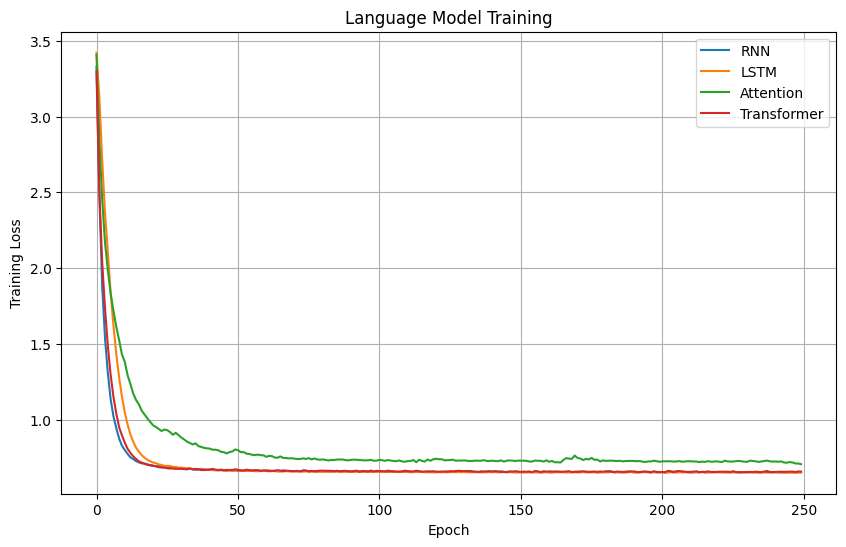

In [47]:
# Loss

import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
plt.plot(rnn_losses, label="RNN")
plt.plot(lstm_losses, label="LSTM")
plt.plot(att_loss, label="Attention")
plt.plot(trns_loss, label="Transformer")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Language Model Training")
plt.legend()
plt.grid()
plt.show()

In [53]:
# Real Data의 활용

from google.colab import drive
drive.mount('/content/drive')

filename = '/content/drive/MyDrive/Colab Notebooks/transcript.txt'

def load_berp_sentences(filename):

    sentences = []
    with open(filename, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split(maxsplit=1)
            if len(parts) != 2:
                continue
            sentence = parts[1].lower()
            sentences.append(sentence)
    return sentences

sentences = load_berp_sentences(filename)
print("Numbder of sentences", len(sentences))

# 10문장 뽑기
for sen in sentences[:10]:
    print(sen)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Numbder of sentences 8566
okay let's see i want to go to a thai restaurant . [uh] with less than ten dollars per person
<i> <like> <to> <eat> [uh] i like to eat at lunch time . so that would be eleven a__m to one p__m
i don't want to walk for more than five minutes
tell me more about the [uh] na- nakapan [uh] restaurant on martin luther king
i like to go to a hamburger restaurant
let's start again
i like to get a hamburger at an american restaurant
i'd like to eat dinner . and i don't mind walking [uh] . for half an hour
i don't want to spend more than [uh] ten dollars for a hamburger
<(te)-ll> <me> <more> <about> <the> <two> <barbecue> <restaurants> tell me more about the two barbecue restaurants you listed


In [54]:
# Real Data를 하이퍼파라미터 바꿔가며 실시하기

# 2000 문장만 사용
import random
random.seed(44)
random.shuffle(sentences)
sentences = sentences[:2000]

# 2000문장 뽑고난 뒤의 단어장 생성
words = []
for sentence in sentences:
    words.extend(sentence.lower().split())

vocab = SPECIAL_TOKENS + sorted(set(words))
word_to_id = {word: i for i, word in enumerate(vocab)}
id_to_word = {i: word for word, i in word_to_id.items()}

PAD_ID = word_to_id["<pad>"]
BOS_ID = word_to_id["<bos>"]
EOS_ID = word_to_id["<eos>"]
UNK_ID = word_to_id["<unk>"]
vocab_size = len(vocab)

MAX_LEN = 20    # 추후 값을 늘려주면서 진행해보기!!

dataset = LanguageModelDataset(sentences)
loader = DataLoader(dataset, batch_size=128, shuffle=True)   # batch 64로 다시 만들기 , 추후 값을 변경해보기

In [55]:
epochs = 500


print("attention\n")
attention_berp = AttentionLanguageModel(
    vocab_size=vocab_size,
    max_len=MAX_LEN
).to(device)

att_berp_loss = train_model(attention_berp, loader, epochs)

print("\ntransformer")
transformer_berp = TransformerLanguageModel(
    vocab_size=vocab_size,
    embedding_dim=64,
    num_heads=4,
    ff_dim=1024,
    max_len=MAX_LEN
).to(device)

trns_berp_loss = train_model(transformer_berp, loader, epochs)

attention

Epoch:  50, Loss: 1.9237
Epoch: 100, Loss: 1.5187
Epoch: 150, Loss: 1.3748
Epoch: 200, Loss: 1.2969
Epoch: 250, Loss: 1.2487
Epoch: 300, Loss: 1.2087

transformer
Epoch:  50, Loss: 1.0812
Epoch: 100, Loss: 1.0400
Epoch: 150, Loss: 1.0282
Epoch: 200, Loss: 1.0201
Epoch: 250, Loss: 1.0156
Epoch: 300, Loss: 1.0071


[i want]
  Attention  : i want to eat some [uh] pasta and [um] meat and vegetables
  Transformer: i want to go there this weekend
[i would like]
  Attention  : i would like to have lunch today
  Transformer: i would like to eat on a weekday
[show me]
  Attention  : show me the list of restaurants in berkeley . [tap]
  Transformer: show me the information about oliveto's
[can you]
  Attention  : can you give me a list of restaurants around i__c__s__i in walking distance twenty
  Transformer: can you give me a saturday as well
[where can]
  Attention  : where can i get a cup of coffee and donuts in the morning
  Transformer: where can i get an american breakfast
[]
  Attention  : i'm willing to travel about thirty minutes or less from i__c__s-(_i)
  Transformer: i want to eat on a monday
Attention   153,017
Transformer 289,785


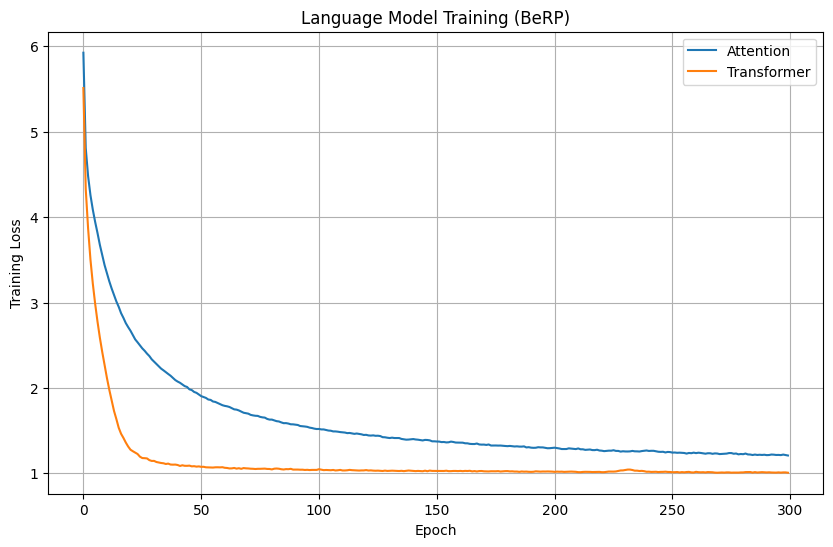

In [56]:
# 생성 + 파라미터 수 + loss 그래프
prompts = ["i want", "i would like", "show me", "can you", "where can", ""]
for prompt in prompts:
    print(f"[{prompt}]")
    print("  Attention  :", generate_text(attention_berp, prompt=prompt))
    print("  Transformer:", generate_text(transformer_berp, prompt=prompt))

print("Attention  ", f"{count_parameters(attention_berp):,}")
print("Transformer", f"{count_parameters(transformer_berp):,}")

plt.figure(figsize=(10, 6))
plt.plot(att_berp_loss, label="Attention")
plt.plot(trns_berp_loss, label="Transformer")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Language Model Training (BeRP)")
plt.legend()
plt.grid()
plt.show()

# 하이퍼 파라미터 관련 내용을 정리하기


| 그룹 | 하이퍼파라미터 | 현재 값 | 올리면 시간 | 올리면 성능 | 비고 |
|---|---|---|---|---|---|
| 데이터 | num_sentences | 2,000 | 정비례 증가 | 좋아짐 | 단어장(vocab)도 커져서 파라미터 수 증가 |
| 데이터 | seed | 44 | 영향 없음 | 영향 없음 | 어떤 문장이 뽑히는지만 바뀜 |
| 데이터 | MAX_LEN | 20 | 증가 (Attention은 T x T라 제곱) | 긴 문장이 덜 잘림 |  |
| 데이터 | batch_size | 64 | 배치 하나는 조금 증가, 1 epoch당 시간은 감소 |  같은 epoch이면 업데이트 횟수가 줄어 loss가 덜 내려갈 수 있음 (loss는 평균이라 보폭은 그대로) | lr을 함께 키우거나 epoch를 늘려 보완
| 모델 | embedding_dim | 64 | 증가 | 표현력 증가, 과적합 위험 |  |
| 모델 | num_heads | 4 | 거의 그대로 | 다양한 관계 학습 | Transformer만, embedding_dim을 나누어떨어지게 |
| 모델 | ff_dim | 128 | 증가 | FFN 표현력 증가 | Transformer만 |
| 학습 | epochs | 300 | 정비례 증가 | train loss는 계속 감소, val loss는 어느 순간 다시 증가 | 과적합 지점에서 멈추기 (Early Stopping) |
| 학습 | learning_rate | 0.003 | 영향 없음 | 너무 크면 발산, 너무 작으면 느림 |  |
| 생성 | temperature | 0.8 | 영향 없음 | 높으면 다양하고 엉뚱, 낮으면 무난하고 반복적 | 재학습 불필요, logits를 나눈 뒤 softmax |
| 생성 | top_k | 3 | 영향 없음 | 높으면 다양, 1이면 항상 같은 문장 | 재학습 불필요 |
| 생성 | max_new_tokens | 12 | 생성 시간만 증가 | 더 긴 문장 가능 | 재학습 불필요 |
